In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [87]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [88]:
df = pd.read_csv("data/datav3.csv")

df.head()

,customer_id,observation_month,branch_id,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,device_type,region,app_theme,education_level,marketing_channel,campaign_code,noise_feature_1,noise_feature_2,noise_feature_3,purchased
0,CUST01723,2026-06-01,B24,57,4144.46,49861.80,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,Desktop,West,Dark,Bachelor,Organic,CMP60,-0.3758,0.7415,1,0
1,CUST03090,2025-11-01,B05,39,3313.13,39964.60,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,Mobile,Central,System,Bachelor,Email,CMP02,-0.6708,0.5766,1,0
2,CUST04684,2026-01-01,B13,51,4965.57,58703.65,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,Mobile,North,Light,Master,Organic,CMP04,0.2868,-0.6751,0,0
3,CUST01687,2025-03-01,B05,56,2045.66,24364.68,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,Mobile,Central,Dark,Bachelor,Social,CMP10,2.1992,0.8292,1,0
4,CUST00535,2025-11-01,B17,31,4355.62,51882.27,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,Desktop,South,Dark,Bachelor,Search,CMP01,-1.2592,-0.1662,1,0


In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7519 entries, 0 to 7518
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               7519 non-null   str    
 1   observation_month         7519 non-null   str    
 2   branch_id                 7519 non-null   str    
 3   age                       7519 non-null   int64  
 4   monthly_income            7519 non-null   float64
 5   annual_income             7519 non-null   float64
 6   website_visits_30d        7519 non-null   int64  
 7   website_visits_90d        7519 non-null   int64  
 8   session_minutes           7519 non-null   float64
 9   discount_pct              7519 non-null   float64
 10  support_tickets_30d       7519 non-null   int64  
 11  premium_member            7519 non-null   int64  
 12  days_since_last_purchase  7519 non-null   float64
 13  cart_items                7519 non-null   int64  
 14  email_opens_30d    

In [90]:
df.shape

(7519, 29)

# Data Preprocessing 

## Encoding Categorical features

### Dummy Encoding

In [91]:
df.head()

,customer_id,observation_month,branch_id,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,device_type,region,app_theme,education_level,marketing_channel,campaign_code,noise_feature_1,noise_feature_2,noise_feature_3,purchased
0,CUST01723,2026-06-01,B24,57,4144.46,49861.80,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,Desktop,West,Dark,Bachelor,Organic,CMP60,-0.3758,0.7415,1,0
1,CUST03090,2025-11-01,B05,39,3313.13,39964.60,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,Mobile,Central,System,Bachelor,Email,CMP02,-0.6708,0.5766,1,0
2,CUST04684,2026-01-01,B13,51,4965.57,58703.65,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,Mobile,North,Light,Master,Organic,CMP04,0.2868,-0.6751,0,0
3,CUST01687,2025-03-01,B05,56,2045.66,24364.68,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,Mobile,Central,Dark,Bachelor,Social,CMP10,2.1992,0.8292,1,0
4,CUST00535,2025-11-01,B17,31,4355.62,51882.27,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,Desktop,South,Dark,Bachelor,Search,CMP01,-1.2592,-0.1662,1,0


In [92]:
dummy_encoding_columns = ['device_type', 'region', 'app_theme', 'marketing_channel']

dummy_encoded_df = pd.get_dummies(
    df[dummy_encoding_columns],
    drop_first=True,
    dtype=int
)

dummy_encoded_df.head()

,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social
0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0,1,1,0,0,0,0,0
2,1,0,0,1,0,0,1,0,0,1,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,1,0,0,0,0,0,0,0,1,0


In [93]:
df_clean = pd.concat([df, dummy_encoded_df], axis=1)

### Ordinary Encoding

In [94]:
df['education_level'].value_counts()

education_level
Bachelor       3140
High School    2090
Master         1771
PhD             518
Name: count, dtype: int64

In [95]:
education_level_mapping = {
    "High School":1,
    "Bachelor":2,
    "Master":3,
    "PhD":4
}

df_clean['education_level'] = df_clean['education_level'].map(education_level_mapping)

## TimeStamp column

Observation-month data is  in timestamp format like '2022-02-08'. We need to convert it into numeric values: How many months have passed since the first date in the dataset. 

In [96]:
df_clean['observation_month'] = pd.to_datetime(df_clean['observation_month'])

# getting start date
start_date = df_clean['observation_month'].min()

# calculating months-since-start
df_clean['months_since_start'] = (
    (df_clean['observation_month'].dt.year - start_date.year) * 12
    + 
    (df_clean['observation_month'].dt.month - start_date.month) 
)

## Dropping Columns

dropping Pure identifier columns, encoded columns, timestamp column and target columns

In [97]:
df_clean.head()

,customer_id,observation_month,branch_id,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,device_type,region,app_theme,education_level,marketing_channel,campaign_code,noise_feature_1,noise_feature_2,noise_feature_3,purchased,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
0,CUST01723,2026-06-01,B24,57,4144.46,49861.80,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,Desktop,West,Dark,2,Organic,CMP60,-0.3758,0.7415,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,17
1,CUST03090,2025-11-01,B05,39,3313.13,39964.60,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,Mobile,Central,System,2,Email,CMP02,-0.6708,0.5766,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,10
2,CUST04684,2026-01-01,B13,51,4965.57,58703.65,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,Mobile,North,Light,3,Organic,CMP04,0.2868,-0.6751,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,12
3,CUST01687,2025-03-01,B05,56,2045.66,24364.68,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,Mobile,Central,Dark,2,Social,CMP10,2.1992,0.8292,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2
4,CUST00535,2025-11-01,B17,31,4355.62,51882.27,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,Desktop,South,Dark,2,Search,CMP01,-1.2592,-0.1662,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,10


In [98]:
dropping_columns = [
    'customer_id', 
    'observation_month', 
    'branch_id', 
    'device_type', 
    'region', 
    'app_theme', 
    'marketing_channel', 
    'campaign_code',
    'purchased'
]

df_clean = df_clean.drop(columns=dropping_columns)
df_clean.head()

,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,education_level,noise_feature_1,noise_feature_2,noise_feature_3,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
0,57,4144.46,49861.80,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,2,-0.3758,0.7415,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,17
1,39,3313.13,39964.60,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,2,-0.6708,0.5766,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,10
2,51,4965.57,58703.65,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,3,0.2868,-0.6751,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,12
3,56,2045.66,24364.68,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,2,2.1992,0.8292,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2
4,31,4355.62,51882.27,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,2,-1.2592,-0.1662,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,10


In [99]:
df_clean.shape

(7519, 35)

## Standardization

In [100]:
def z_score_stand(data):
    mean = data.mean()
    std = data.std()

    return (data - mean) / std

# Absence of multicollinearity 

In [101]:
df_clean.head()

,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,education_level,noise_feature_1,noise_feature_2,noise_feature_3,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
0,57,4144.46,49861.80,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,2,-0.3758,0.7415,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,17
1,39,3313.13,39964.60,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,2,-0.6708,0.5766,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,10
2,51,4965.57,58703.65,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,3,0.2868,-0.6751,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,12
3,56,2045.66,24364.68,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,2,2.1992,0.8292,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2
4,31,4355.62,51882.27,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,2,-1.2592,-0.1662,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,10


## Correlation Heatmap

In [102]:
corr_matrix = df_clean.corr()
corr_matrix

,age,monthly_income,annual_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,education_level,noise_feature_1,noise_feature_2,noise_feature_3,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
age,1.000000,0.008835,0.008830,0.003596,0.001180,-0.000434,0.010575,-0.003562,-0.007358,0.014629,-0.006427,-0.003714,0.006353,0.009913,-0.001586,0.019367,0.040605,-0.000940,0.019627,0.009638,0.007236,-0.008604,-0.006273,0.012043,-0.005591,-0.025876,-0.001260,-0.001122,0.002836,0.002568,-0.017343,0.001341,0.006876,-0.004839,0.013860
monthly_income,0.008835,1.000000,0.999790,0.240310,0.222211,0.051795,0.032680,-0.006609,0.157457,-0.002893,0.079844,0.133785,0.093547,0.038924,0.037581,-0.001708,0.404182,0.007446,-0.019421,-0.005234,0.003316,0.004443,0.018438,0.009001,-0.024063,0.008053,-0.006982,0.002160,0.009368,0.000126,-0.005976,0.002853,-0.002095,0.007291,-0.018372
annual_income,0.008830,0.999790,1.000000,0.240132,0.222046,0.051643,0.032467,-0.006405,0.157015,-0.002637,0.079659,0.133619,0.093385,0.039166,0.037616,-0.001304,0.404218,0.007130,-0.019194,-0.005069,0.003023,0.005047,0.018709,0.008653,-0.023977,0.008026,-0.007034,0.001990,0.009321,0.000233,-0.006035,0.002764,-0.002140,0.007370,-0.018521
website_visits_30d,0.003596,0.240310,0.240132,1.000000,0.943254,0.189716,0.056742,-0.009721,0.356427,-0.025795,0.310594,0.539742,0.435803,0.210680,0.049794,0.022387,0.110552,0.004242,0.003141,0.010635,0.006061,0.004269,0.011472,0.001496,-0.010468,0.003487,0.014571,0.009734,-0.006269,0.013344,-0.008317,0.007031,-0.015613,-0.000233,-0.002898
website_visits_90d,0.001180,0.222211,0.222046,0.943254,1.000000,0.181880,0.056697,-0.012926,0.335490,-0.027966,0.294131,0.507119,0.404454,0.196355,0.042735,0.016748,0.099986,-0.003690,-0.001018,0.004849,0.007404,0.005041,0.005754,-0.002636,-0.003356,0.007197,0.016625,0.000729,-0.002400,0.012392,-0.007236,0.009302,-0.014229,-0.005820,-0.002482
session_minutes,-0.000434,0.051795,0.051643,0.189716,0.181880,1.000000,0.003462,0.013882,0.084495,0.012653,0.057150,0.098723,0.060169,0.030884,0.026738,0.001343,0.033904,0.016546,-0.013256,0.021567,0.020466,-0.007820,0.001377,-0.004272,0.008410,0.004957,-0.005494,0.019402,0.000908,-0.007535,-0.001736,0.018932,-0.010003,0.004084,0.007132
discount_pct,0.010575,0.032680,0.032467,0.056742,0.056697,0.003462,1.000000,0.004025,0.183739,-0.018223,0.035412,0.072504,0.026283,0.024663,0.021543,0.010734,0.023440,-0.027769,-0.001633,0.000972,-0.008603,0.009180,-0.007033,0.020916,-0.009494,-0.008273,-0.011635,-0.000566,0.000273,-0.001154,0.017739,0.002906,-0.004288,0.002413,-0.000088
support_tickets_30d,-0.003562,-0.006609,-0.006405,-0.009721,-0.012926,0.013882,0.004025,1.000000,-0.003991,-0.006515,-0.004734,-0.004624,-0.003057,-0.010698,-0.103844,0.017327,0.004336,-0.011872,0.000419,-0.015989,0.011344,-0.011437,-0.007055,-0.009664,0.054917,-0.013300,0.007364,0.010494,-0.017357,0.014453,0.003509,0.004509,-0.002919,-0.006614,-0.010904
premium_member,-0.007358,0.157457,0.157015,0.356427,0.335490,0.084495,0.183739,-0.003991,1.000000,-0.066882,0.250208,0.364978,0.160879,0.063831,0.151110,0.004311,0.095466,-0.016244,0.013028,0.002334,-0.017792,-0.009660,0.011269,0.002628,0.002603,-0.013945,0.008619,-0.005529,0.008915,-0.012191,0.017835,-0.000589,-0.001158,0.006886,-0.017450
days_since_last_purchase,0.014629,-0.002893,-0.002637,-0.025795,-0.027966,0.012653,-0.018223,-0.006515,-0.066882,1.000000,-0.033593,-0.011219,-0.016546,0.012574,-0.036805,-0.000759,-0.024889,-0.018727,-0.004758,0.004178,-0.017808,0.009670,0.013310,0.008144,-0.022042,-0.014388,-0.001200,0.014123,0

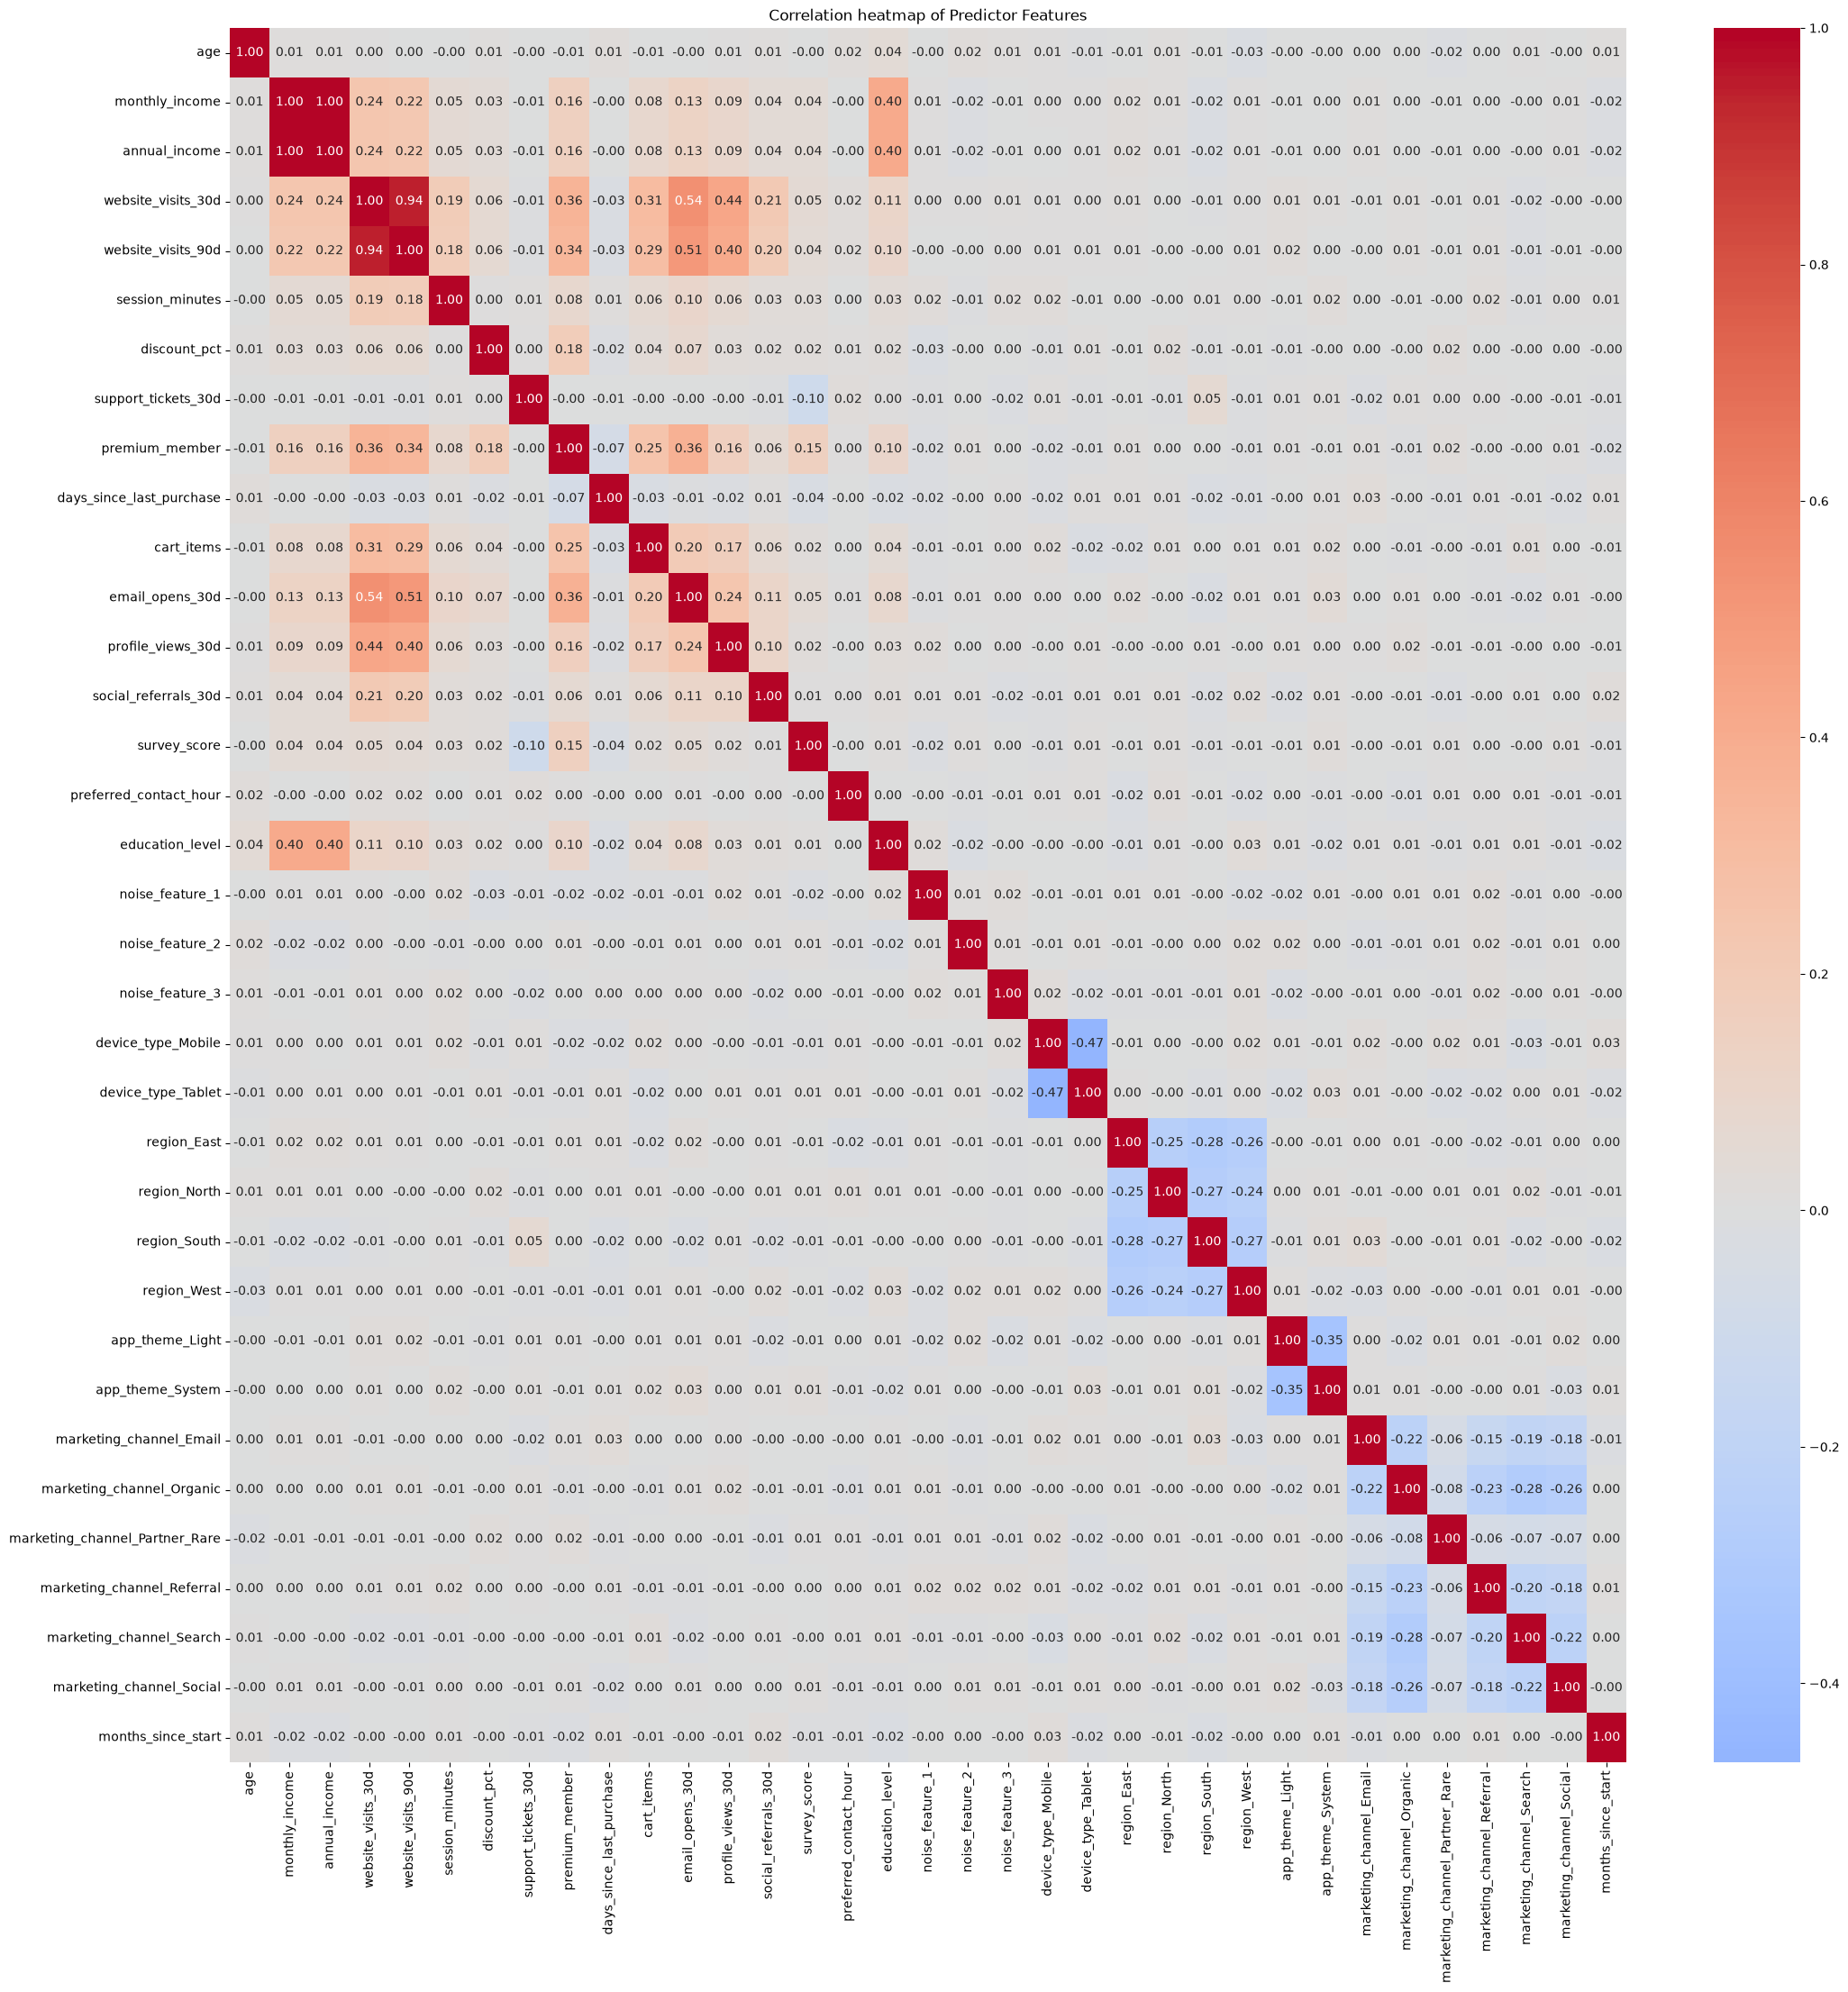

In [103]:
plt.figure(figsize=(25, 25))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Correlation heatmap of Predictor Features")
plt.show()

In [104]:
# converting correlation matrix to Data Frame 
# keeping only uppder traiangle
upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)
# converting to DataFrame
corr_pairs = (
    upper
    .stack()
    .reset_index()
)
corr_pairs.columns = [
    'feature_a',
    'feature_b',
    'correlation'
]
corr_pairs['abs_correlation'] = (
    corr_pairs['correlation'].abs()
)


corr_pairs = corr_pairs.sort_values(by='abs_correlation', ascending=False)
corr_pairs.head(30)

,feature_a,feature_b,correlation,abs_correlation
37,monthly_income,annual_income,0.999790,0.999790
109,website_visits_30d,website_visits_90d,0.943254,0.943254
116,website_visits_30d,email_opens_30d,0.539742,0.539742
151,website_visits_90d,email_opens_30d,0.507119,0.507119
721,device_type_Mobile,device_type_Tablet,-0.466775,0.466775
117,website_visits_30d,profile_views_30d,0.435803,0.435803
152,website_visits_90d,profile_views_30d,0.404454,0.404454
86,annual_income,education_level,0.404218,0.404218
51,monthly_income,education_level,0.404182,0.404182
291,premium_member,email_opens_30d,0.364978,0.364978


In [105]:
len(corr_pairs[corr_pairs['correlation'] >= 0.10])

35

Conclusion:
- `monthly_income` and `annual_income` have an extremely strong positive correlation, `r=0.99`.They are essentially redundant, so I drop reasonably remove one of them for example `annual_income`.
- `website_visits_30d` and `website_visits_90d` have a strong positive correlation, `r=0.94`. This indicates potential multicollinearity, I will invistigate further with `VIF` before deciding which feature to remove.
- `website_visits_30d` and `email_opens_30d` have moderate correlation `r=0.54`. This alone is not serve enough to remove either feature.`VIF` will determine whether they contribute to multicollinearity jointly other predictors.
- `website_visits_90d ` and `email_opens_30d` have moderate correlation `r=0.50`. Again, I will invistigate further.
- Other correlations are mostly weak or moderate and do not show obvious pairwise multicollinearity.

In [106]:
# dropping "annual_income"  feature
df_clean = df_clean.drop(columns='annual_income')
df_clean.head()

,age,monthly_income,website_visits_30d,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,education_level,noise_feature_1,noise_feature_2,noise_feature_3,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
0,57,4144.46,8,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,2,-0.3758,0.7415,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,17
1,39,3313.13,7,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,2,-0.6708,0.5766,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,10
2,51,4965.57,3,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,3,0.2868,-0.6751,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,12
3,56,2045.66,7,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,2,2.1992,0.8292,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2
4,31,4355.62,10,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,2,-1.2592,-0.1662,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,10


## Variance Inflation Factor

### website_visits_30d feature

In [107]:
X_website_visits_30d = df_clean.drop(columns='website_visits_30d')
y_website_visits_30d = df_clean['website_visits_30d']


X_website_visits_30d_stand = z_score_stand(X_website_visits_30d)


I will apply OLS model since target is continuous variabel

In [108]:
# adding intercetpt to features
ones = np.ones((X_website_visits_30d.shape[0], 1))
X_website_visits_30d_stand_incercept = np.hstack((ones, X_website_visits_30d_stand))

# Training OLS 
beta_hat_website_visits_30d = (
    np.linalg.pinv(
        X_website_visits_30d_stand_incercept.T @ X_website_visits_30d_stand_incercept
    ) @ X_website_visits_30d_stand_incercept.T @ y_website_visits_30d
)

# making predictions
website_visits_30d_predictions = X_website_visits_30d_stand_incercept @ beta_hat_website_visits_30d

In [109]:
# calculating residuals
website_visits_30d_residuals = y_website_visits_30d - website_visits_30d_predictions

# Calculating SSE(unexplained variation)
website_visits_30d_SSE = np.sum(website_visits_30d_residuals ** 2)

# Calculating SST(total variation)
mean_website_visits_30d = np.mean(y_website_visits_30d)
website_visits_30d_SST = np.sum((y_website_visits_30d - mean_website_visits_30d) ** 2)

# Calculating R² (How much of the variation in the target does the model explain)
website_visits_30d_Rsquared = 1 - (website_visits_30d_SSE / website_visits_30d_SST)

# Calculating Tolerance (How much of the variation in the target doesn't the model explain)
website_visits_30d_Tolerance = 1 - website_visits_30d_Rsquared

# Variance Inflation Factor
website_visits_30d_VIF = 1 / website_visits_30d_Tolerance


print(F"Unexplained Variantion: {website_visits_30d_SSE}")
print(F"Total Variantion: {website_visits_30d_SST}")
print(F"Explained Variation: {website_visits_30d_Rsquared}")
print(F"Unexplained Variation (%): {website_visits_30d_Tolerance}")
print(f"VIF: {website_visits_30d_VIF}")

Unexplained Variantion: 6949.680202643689
Total Variantion: 70356.02048144699
Explained Variation: 0.9012212436819628
Unexplained Variation (%): 0.09877875631803723
VIF: 10.1236342435848


Approximately `90%` of the variation in `website_visits_30d` can be explained linearly by all the other predictors together. Only about `10%` of its variation is not explained by those predictors. The VIF is `10.1`, meaning the variance of the estimated coefficient for `website_visits_30d` is about `10.1` times larger than it would be if `website_visits_30d` were not linearly related to the other predictors. Therefore, `website_visits_30d` has a `severe multicollinearity` problem. So I drop this feature 

In [110]:
df_clean = df_clean.drop(columns='website_visits_30d')

df_clean.head()

,age,monthly_income,website_visits_90d,session_minutes,discount_pct,support_tickets_30d,premium_member,days_since_last_purchase,cart_items,email_opens_30d,profile_views_30d,social_referrals_30d,survey_score,preferred_contact_hour,education_level,noise_feature_1,noise_feature_2,noise_feature_3,device_type_Mobile,device_type_Tablet,region_East,region_North,region_South,region_West,app_theme_Light,app_theme_System,marketing_channel_Email,marketing_channel_Organic,marketing_channel_Partner_Rare,marketing_channel_Referral,marketing_channel_Search,marketing_channel_Social,months_since_start
0,57,4144.46,25,18.74,9.01,3,1,16.1,2,11,2,1,5,17,2,-0.3758,0.7415,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,17
1,39,3313.13,27,12.38,7.64,1,1,6.6,0,11,6,1,7,8,2,-0.6708,0.5766,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,10
2,51,4965.57,15,8.97,15.84,3,0,55.0,0,3,5,1,4,8,3,0.2868,-0.6751,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,12
3,56,2045.66,24,30.73,10.50,0,0,22.8,0,6,8,0,5,8,2,2.1992,0.8292,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2
4,31,4355.62,29,31.40,2.09,0,0,40.1,1,10,4,0,8,8,2,-1.2592,-0.1662,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,10


### website_visits_90d feature


In [111]:
website_visits_90d_X = df_clean.drop(columns='website_visits_90d')
y_website_visits_90d = df_clean['website_visits_90d']

website_visits_90d_X = z_score_stand(website_visits_90d_X)

In [112]:
# adding intercept to features
ones = np.ones((website_visits_90d_X.shape[0], 1))
X_website_visits_90_with_intercetp = np.hstack((ones, website_visits_90d_X))

# Training OLS model
beta_hat_website_visits_90d = (
    np.linalg.pinv(
        X_website_visits_90_with_intercetp.T @ X_website_visits_90_with_intercetp
    ) @ X_website_visits_90_with_intercetp.T @ y_website_visits_90d
)

# making predictions 
website_visits_90d_predictions = X_website_visits_90_with_intercetp @ beta_hat_website_visits_90d

In [114]:
# calculating residuals 
website_visits_90d_residuals = y_website_visits_90d - website_visits_90d_predictions

# Calculating SSE (unexplained variation)
website_visits_90d_SSE = np.sum(website_visits_90d_residuals ** 2)

# Calculating SST (total variance)
mean_website_visits_90d = np.mean(y_website_visits_90d)
website_visits_90d_SST = np.sum((y_website_visits_90d - mean_website_visits_90d) ** 2)

# Calculating R² (How much of the variation in the target does the model explain)
website_visits_90d_Rsquard = 1 - (website_visits_90d_SSE / website_visits_90d_SST)

# calculating Tolerance (how much of the variation in the target doesn't the model explain)
website_visits_90d_Tolerance = 1 - website_visits_90d_Rsquard

# VIF (variance inflation factior)
website_visits_90d_VIF = 1 / website_visits_90d_Tolerance


print(F"SSE Unexplained Variantion: {website_visits_90d_SSE}")
print(F"SST Total Variantion: {website_visits_90d_SST}")
print(F"R² Explained Variation: {website_visits_90d_Rsquard}")
print(F"Tolerance Unexplained Variation (%): {website_visits_90d_Tolerance}")
print(f"VIF: {website_visits_90d_VIF}")

SSE Unexplained Variantion: 360071.72444484476
SST Total Variantion: 621226.0877776301
R² Explained Variation: 0.42038537735438175
Tolerance Unexplained Variation (%): 0.5796146226456182
VIF: 1.7252842853335142


After I drop the `website_visits_30d` which has a strong postive correlation with `website_visits_90d`.
Approximaltey `42%` of the variation in `website_visits_90d` can be explained linearyly by all the other predictiors together. About `58%` of it's variation is not explained by those predictiors. The VIF is `1.7`, meaning the variance of the estimated coefficient for `website_visits_90d` is about `1.7` times larger than it would be if `website_visits_90d` were not linearly related to the other predictors.

### email_opens_30d feature

In [115]:
X_email_opens_30d = df_clean.drop(columns='email_opens_30d')
y_email_opens_30d = df_clean['email_opens_30d']


X_email_opens_30d = z_score_stand(X_email_opens_30d)

In [116]:
# adding intercetpt to features
ones = np.ones((X_email_opens_30d.shape[0], 1))
X_email_opens_30d_with_incercept = np.hstack((ones, X_email_opens_30d))

# Training OLS 
beta_hat_email_opens_30d = (
    np.linalg.pinv(
        X_email_opens_30d_with_incercept.T @ X_email_opens_30d_with_incercept
    ) @ X_email_opens_30d_with_incercept.T @ y_email_opens_30d
)

# making predictions
email_opens_30d_predictions = X_email_opens_30d_with_incercept @ beta_hat_email_opens_30d

In [117]:
# calculating residuals
email_opens_30d_residuals = y_email_opens_30d - email_opens_30d_predictions

# Calculating SSE(unexplained variation)
email_opens_30d_SSE = np.sum(email_opens_30d_residuals ** 2)

# Calculating SST(total variation)
mean_email_opens_30d = np.mean(y_email_opens_30d)
email_opens_30d_SST = np.sum((y_email_opens_30d - mean_email_opens_30d) ** 2)

# Calculating R² (How much of the variation in the target does the model explain)
email_opens_30d_Rsquared = 1 - (email_opens_30d_SSE / email_opens_30d_SST)

# Calculating Tolerance (How much of the variation in the target doesn't the model explain)
email_opens_30d_Tolerance = 1 - email_opens_30d_Rsquared

# Variance Inflation Factor
email_opens_30d_VIF = 1 / email_opens_30d_Tolerance


print(F"Unexplained Variantion: {email_opens_30d_SSE}")
print(F"Total Variantion: {email_opens_30d_SST}")
print(F"Explained Variation: {email_opens_30d_Rsquared}")
print(F"Unexplained Variation (%): {email_opens_30d_Tolerance}")
print(f"VIF: {email_opens_30d_VIF}")

Unexplained Variantion: 70600.52048006452
Total Variantion: 101479.22489692777
Explained Variation: 0.30428597033754134
Unexplained Variation (%): 0.6957140296624587
VIF: 1.437372192257173


`email_opens_30d` has a moderate positive correlation with `website_visits_90d` `(\(r \approx 0.51\))`. However, its VIF is only approximately `1.44`. About `30%` of its variation is explained by all the other predictors together, while about` 70%` remains unexplained. Therefore, `email_opens_30d` does not show problematic multicollinearity and does not need to be removed.

### device_type_Mobile

In [118]:
# selecting data 
X_device_type_Mobile = df_clean.drop(columns='device_type_Mobile')
y_device_type_Mobile = df_clean['device_type_Mobile']

# Standardization 
X_device_type_Mobile = z_score_stand(X_device_type_Mobile)

# adding intercetpt to features
ones = np.ones((X_device_type_Mobile.shape[0], 1))
X_device_type_Mobile_with_incercept = np.hstack((ones, X_device_type_Mobile))

# Training OLS 
beta_hat_device_type_Mobile = (
    np.linalg.pinv(
        X_device_type_Mobile_with_incercept.T @ X_device_type_Mobile_with_incercept
    ) @ X_device_type_Mobile_with_incercept.T @ y_device_type_Mobile
)

# making predictions
device_type_Mobile_predictions = X_device_type_Mobile_with_incercept @ beta_hat_device_type_Mobile


In [119]:
# calculating residuals
device_type_Mobile_residuals = y_device_type_Mobile - device_type_Mobile_predictions

# Calculating SSE(unexplained variation)
device_type_Mobile_SSE = np.sum(device_type_Mobile_residuals ** 2)

# Calculating SST(total variation)
mean_device_type_Mobile = np.mean(y_device_type_Mobile)
device_type_Mobile_SST = np.sum((y_device_type_Mobile - mean_device_type_Mobile) ** 2)

# Calculating R² (How much of the variation in the target does the model explain)
device_type_Mobile_Rsquared = 1 - (device_type_Mobile_SSE / device_type_Mobile_SST)

# Calculating Tolerance (How much of the variation in the target doesn't the model explain)
device_type_Mobile_Tolerance = 1 - device_type_Mobile_Rsquared

# Variance Inflation Factor
device_type_Mobile_VIF = 1 / device_type_Mobile_Tolerance


print(F"Unexplained Variantion: {device_type_Mobile_SSE}")
print(F"Total Variantion: {device_type_Mobile_SST}")
print(F"Explained Variation: {device_type_Mobile_Rsquared}")
print(F"Unexplained Variation (%): {device_type_Mobile_Tolerance}")
print(f"VIF: {device_type_Mobile_VIF}")

Unexplained Variantion: 1429.532413327454
Total Variantion: 1839.2988429312402
Explained Variation: 0.22278404141806163
Unexplained Variation (%): 0.7772159585819384
VIF: 1.2866436785787827
